In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
# This cell should be the only one that changes, as this is where the dataset and corresponding sample information
date = '[date]'
df = pd.read_excel('[file path]', header=0) # Make sure to change header depending on your data file

# Make sure sample names is in same order as data
C = ['C1','C2','C3']
I = ['I1','I2','I3']
A = ['A1','A2','A3']
D = ['D1','D2','D3']

sample_names = C + I + A + D

# sample_names_plotting controls display/output order only, independent of the data's actual
sample_names_plotting = C + I + A + D

groups = {'C':C, 'I':I, 'A':A, 'D':D}

hue_order_list = None

num_fatty_acid_columns = 3


## Functions

In [29]:
def strfilter(func, s: str) -> str:
    """
    Return a string containing all characters in s such that func(s) is true.
    """
    return ''.join(i for i in s if func(i))
def get_sat(s):
    new = ''
    i = 0
    while not str.isdecimal(s[i]):
        i += 1
    while i < len(s) and str.isdecimal(s[i]):
        new += s[i]
        i += 1
    return new
def average_samples(data):
    for k, v in groups.items():
        if len(v) > 1:
            data[k] = data.loc[:, v].mean(axis=1)
    return data
def name_map(name: str) -> str:
    for k, v in groups.items():
        if name in v:
            return k
    return name

In [ ]:
# constants
phospholipids = ['PC', 'PE', 'LPC', 'LPE', 'PS', 'LPS', 'PG', 'LPG', 'PA',
                 'LPA', 'PI', 'LPI', 'PIP', 'PIP2', 'PIP3', 'CL', 'PGP',
                 'PPA', 'CDP-DG', 'PEt', 'LPEt', 'LBPA']

INCLUDE_SM_IN_PHOSPHO_TOTAL = True
NON_LIPID_CONTAMINANT_CLASSES = ['DAP', 'Co']

atom_masses = {'C': 12.011, 'N': 14.007, 'H': 1.008, 'O': 15.999, 'P': 30.974}

# Expected number of resolved acyl chains per class, used to identify genuinely fully-resolved
# species (as opposed to un-split composite/combined annotations) before any fatty-acid-level
# quantification.
tails_1 = {i: 1 for i in ['LPC', 'LPE', 'LPS', 'LPG', 'LPA', 'LPI', 'Cer', 'MG', 'ST', 'Hex1Cer',
                          'SQMG', 'MGMG', 'LPEt']}
tails_2 = {i: 2 for i in ['PC', 'PE', 'PS', 'PA', 'PI', 'PIP', 'PIP2', 'PIP3', 'PGP', 'PPA',
                          'CDP-DG', 'DG', 'PG', 'SQDG', 'PEt', 'LBPA']}
tails_3_4 = {'TG': 3, 'CL': 4}

from itertools import chain
tails = dict(chain.from_iterable(d.items() for d in (tails_1, tails_2, tails_3_4)))

sample_columns = ['Area[s1-' + str(sample + 1) + ']' for sample in range(0, len(sample_names))]
fa_columns = ['FA' + str(i) for i in range(1, num_fatty_acid_columns + 1)]


In [31]:
def sum_areas(data):
    """
    Sum the areas corresponding to each fatty acid.
    
    Args:
        data: a pandas dataframe with lipids as index and columns corresponding to
        the fatty acids in each lipid and the area calculated for that lipid in each sample
    Returns:
        a new pandas dataframe with fatty acids as index and columns for each sample, where the
        value at df.loc[fatty_acid, sample] is the sum of the areas for that sample in rows of
        data where fatty_acid is one of the fatty acids in the lipid, counting multiple times if
        the fatty acid appears multiple times in that lipid.
    """
    # we treat '(12:2p)' and '(12:2)' as the same fatty acid
   # data.loc[:, fa_columns] = data.loc[:, fa_columns].applymap(standardize_formula)
    dfs = [data[sample_columns].groupby(data[i]).sum()
           for i in fa_columns]
    return pd.concat(dfs).groupby(level=0).sum()

In [32]:
def is_plausible_fa(formula: str) -> bool:
    """
    Check whether a 'C:D' formula (carbon count : double bonds) is chemically plausible as a
    single fatty acyl chain. This catches un-split composite (multi-chain) annotations that
    happen to still pass the resolved-tail-count check in remove_wrong_fatty_acid_counts
    (e.g. a TG row with 2 columns filled where one of those columns is itself an unresolved
    2-chain remainder like '30:6').

    Rules (based on known animal/avian fatty acid biology):
      - carbon count between 10 and 26 (natural single acyl chains essentially never fall
        outside this range in these lipid classes)
      - no more than 6 double bonds (max seen in natural long-chain PUFAs, e.g. DHA 22:6)
      - enough carbons to physically host that many double bonds (>= 2*double_bonds + 4)
    """
    if pd.isna(formula):
        return True
    try:
        c_str, d_str = str(formula).split(':')
        c = int(get_sat(c_str))
        d = int(get_sat(d_str))
    except (ValueError, IndexError):
        return False
    if c < 10 or c > 26:
        return False
    if d > 6:
        return False
    if d > 0 and c < (2 * d + 4):
        return False
    return True


def remove_wrong_fatty_acid_counts(data):
    """
    Keep only rows where:
      1. the number of filled FA columns matches the expected number of acyl chains for that
         lipid class (from `tails`), AND
      2. every filled FA value is a chemically plausible single fatty acyl chain (see
         is_plausible_fa).

    Rows failing either check are typically un-resolved composite annotations (e.g. '41:3',
    '37:4') rather than real individual fatty acids. Rows whose Class isn't in `tails` at all
    (e.g. SM, Cer, MG - classes we don't have a reliable chain count for, or that are known to
    never be chain-resolved in this dataset) are dropped from this FA-level dataframe by
    design. Use the original, unfiltered `df` (grouped by Class) for total-lipid / class-level
    percentages instead - see the percent_phospho / percent_tg calculation below.
    """
    data = data.copy()
    data['right_fa_count'] = False
    for i, row in data.iterrows():
        cls = row['Class']
        if cls not in tails:
            continue
        n_filled = num_fatty_acid_columns - row[fa_columns].isna().sum()
        if tails[cls] != n_filled:
            continue
        filled_values = [row[c] for c in fa_columns if not pd.isna(row[c])]
        if all(is_plausible_fa(v) for v in filled_values):
            data.loc[i, 'right_fa_count'] = True
    return data[data['right_fa_count']].drop(columns='right_fa_count')


In [33]:
def how_much_saturated(formula: str) -> str:
    """
    From a formula of the form '(14:2)', extract the number of double bonds and return
    the saturation level ('saturated', 'mono', or 'poly').
    """
    double_bonds = int(formula.split(':')[1].split(' ')[0])
    if double_bonds == 0:
        return 'saturated'
    elif double_bonds == 1:
        return 'mono'
    else:
        return 'poly'

In [34]:
def standardize_formula(formula: str) -> str:
    """
    Transform formulas of the form '(12:20p)' to the form '12:20'.
    """
    if pd.isna(formula):
        return formula
    try:
        a, b = formula.split(':')
    except ValueError:
        return formula[1:-1]
    a = get_sat(a)
    b = get_sat(b)
    # a = strfilter(str.isdecimal, a)
    # b = strfilter(str.isdecimal, b)
    return a + ':' + b

In [ ]:
def rename_parts(data):
    """
    Replace the column names 'Area[s-1]', 'Area[s-2]', etc with names corresponding to each sample
    """

    data.columns = sample_names
    return data

In [36]:
def prepare_for_graphing(data):
    """
    Reshape a dataframe for easier graphing.

    Concatenate the columns of a dataframe, adding a column named 'orig_sample' with the original column name,
    a column named 'sample' with the sample condition, and a column named 'kind' with the values of the index.
    """
    dfs = []
    for sample in sample_names:
        a = data.loc[:, sample] \
                .to_frame() \
                .rename(columns={sample: 'fraction'})
        a['orig_sample'] = sample
        dfs.append(a)
    combined = pd.concat(dfs)
    combined['kind'] = combined.index
    combined['sample'] = combined['orig_sample'].map(name_map)
    return combined

In [37]:
def graph_fatty_acids(data, title: str):
    """
    Generate a heat map and bar graph showing the fraction of the most common fatty acids in each sample.
    """
    largest_rows = data \
                    .sum(axis=1) \
                    .sort_values(ascending=False) \
                    .iloc[:15] \
                    .index
    a = data / data.sum()
    a = a.loc[largest_rows, sample_names]
    fig = plt.figure(figsize=(15, 5))
    
    # heatmap
    plt.subplot(1, 2, 1)
    
    ax = sns.heatmap(a[sample_names_plotting], vmin=0, vmax=.35)
    ax.set_title(title)
    ax.set_xlabel('sample')
    
    # bar graph
    plt.subplot(1, 2, 2)
    a = prepare_for_graphing(a)
    ax = sns.barplot(x='kind', y='fraction', hue='sample', hue_order = hue_order_list,data=a, ci=None)
    plt.ylim(0, .35)
    ax.set_title(title)
    ax.set_xlabel('fatty acid')
    fig.autofmt_xdate() # tilt and align the x-axis labels

In [38]:
def graph_saturation(data, title: str):
    """
    Generate a bar graph showing the fraction of saturated fats in each condition.
    """
    a = data.groupby([how_much_saturated(x) for x in data.index]).sum()
    a = a / a.sum()
    plt.ylim(0, .8)
    a = prepare_for_graphing(a)
    ax = sns.barplot(x='sample', y='fraction', hue='kind',data=a, ci=None)
    ax.set_title(title + ' saturated / monounsaturated / polyunsaturated')

In [39]:
def run_pca(data):
    data_pca = data.T.iloc[0:15]

    # normalize to mean 0 and variance 1
    scaler = StandardScaler() 
    scaler.fit(data_pca)
    scaled_data = scaler.transform(data_pca)
    
    # project data onto PCA dimensions
    pca = PCA(n_components = 2)
    pca.fit(scaled_data)
    components = pca.transform(scaled_data)
    
    loading_vectors = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=data_pca.columns)
    pca_values_df = pd.DataFrame(data = components, columns = ['PC1', 'PC2'])
    pca_values_df['sample'] = data_pca.index
    return loading_vectors, pca_values_df

In [40]:
def graph_pca(data, title: str):
    fig = plt.figure(figsize = (8,8))
    data['sample'] = data['sample'].map(name_map)
    ax = sns.scatterplot(x='PC1', y='PC2', hue='sample', hue_order = hue_order_list,data=data, s=100)
    ax.set_xlabel('PC1', fontsize = 15)
    ax.set_ylabel('PC2', fontsize = 15)
    ax.set_title('PCA - ' + title, fontsize = 20)
    ax.grid()

## Data Processing

In [41]:
df_old = df

# df_filtered keeps only chain-resolved, chemically plausible species and is used for all
# FA-level (per-fatty-acid) composition analysis below (sum_areas, graph_fatty_acids,
# graph_saturation, PCA). The original, unfiltered `df` is kept separately and used for the
# total-lipid / class-level percentages (percent_phospho, percent_tg), since those should be
# based on each lipid's actual measured area, not on how many of its chains happened to be
# individually resolved.
df_filtered = remove_wrong_fatty_acid_counts(df)


In [42]:
df_old.shape


(1813, 16)

In [43]:
df_filtered.shape

# QC: how many rows survive the resolved-tail-count + plausibility filter, per class
print(df_filtered['Class'].value_counts())
print()
print('Kept', len(df_filtered), 'of', len(df_old), 'rows for FA-level composition analysis')


Class
TG         383
PC         211
PE         160
DG         134
MG          82
PI          45
PS          30
LPE         29
LPC         28
PG           8
LBPA         3
Hex1Cer      1
PA           1
LPEt         1
Name: count, dtype: int64

Kept 1116 of 1813 rows for FA-level composition analysis


In [44]:
# Total areas for each fatty acid (FA-level composition only - uses the filtered dataframe)
areas_total = rename_parts(sum_areas(df_filtered))


In [45]:
# Phospholipid and triglyceride areas for each fatty acid (FA-level composition only)

df_phospho = df_filtered[df_filtered['Class'].map(lambda x: x in phospholipids)].reset_index()
df_TG = df_filtered[df_filtered['Class'] == 'TG'].reset_index()
areas_tg = rename_parts(sum_areas(df_TG))
areas_phospho = rename_parts(sum_areas(df_phospho))


In [ ]:
# Total phospholipid and triglyceride areas, and percent of total lipid area.
#
# Computed directly from the RAW Area columns grouped by Class in the ORIGINAL (unfiltered) `df`
# - NOT from the FA-decomposed areas_tg / areas_phospho dataframes above
#
# NON_LIPID_CONTAMINANT_CLASSES (e.g. 'DAP' = phthalates) are dropped before computing the total,
# so they don't dilute percent_phospho / percent_tg.

raw_by_sample = df.groupby('Class')[sample_columns].sum()
raw_by_sample.columns = sample_names
raw_by_sample = raw_by_sample.drop(index=NON_LIPID_CONTAMINANT_CLASSES, errors='ignore')

areas_tg_sum = raw_by_sample.loc['TG'].rename('Total TG Areas')

phospho_classes_for_total = list(phospholipids)
if INCLUDE_SM_IN_PHOSPHO_TOTAL and 'SM' in raw_by_sample.index:
    phospho_classes_for_total = phospho_classes_for_total + ['SM']
phospho_classes_for_total = [c for c in phospho_classes_for_total if c in raw_by_sample.index]

areas_phospho_sum = raw_by_sample.loc[phospho_classes_for_total].sum(axis=0).rename('Total Phospho Areas')
areas_total_sum = raw_by_sample.sum(axis=0).rename('Total Areas')

percent_phospho = areas_phospho_sum / areas_total_sum * 100
percent_tg = areas_tg_sum / areas_total_sum * 100
percent_dict = {'Percent Phospho': percent_phospho, 'Percent TG': percent_tg}
percent_total_lipids = pd.DataFrame(data=percent_dict)


In [47]:
# Percent saturation

a = areas_tg.groupby([how_much_saturated(x) for x in areas_tg.index]).sum()
a = a / a.sum()
b = areas_phospho.groupby([how_much_saturated(x) for x in areas_phospho.index]).sum()
b = b / b.sum()

In [48]:
# Save dataframes as xlsx

a.to_excel(date + "_triglycerides_saturated.xlsx")
b.to_excel(date + "_phospholipids_saturated.xlsx")
areas_tg.to_excel(date + "_triglycerides_areas.xlsx")
areas_phospho.to_excel(date + "_phospholipids_areas.xlsx")
percent_total_lipids.to_excel(date + '_percent_of_total_lipids.xlsx')

## Visualizations

C:\Users\steph\AppData\Local\Temp\ipykernel_32792\2106365907.py:24: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(x='kind', y='fraction', hue='sample', hue_order = hue_order_list,data=a, ci=None)
C:\Users\steph\AppData\Local\Temp\ipykernel_32792\2106365907.py:24: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(x='kind', y='fraction', hue='sample', hue_order = hue_order_list,data=a, ci=None)


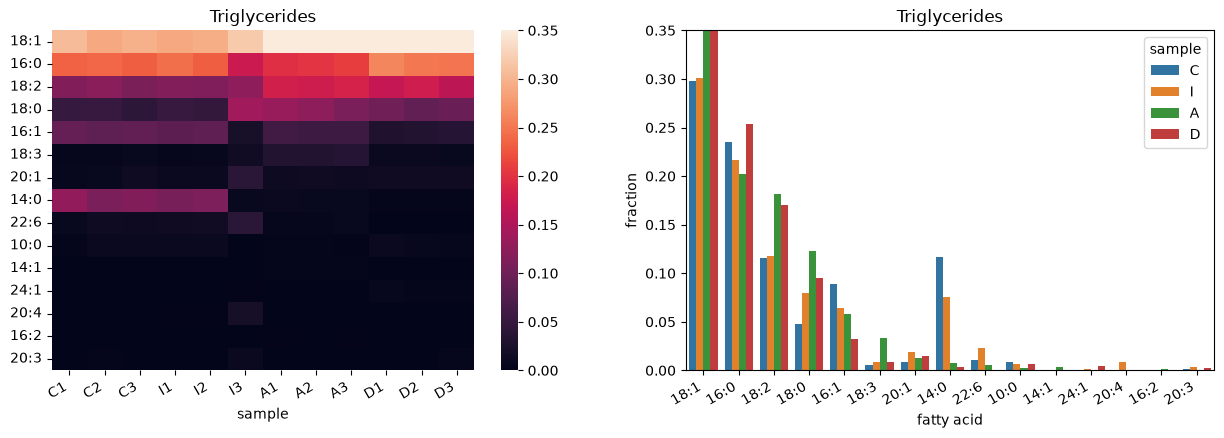

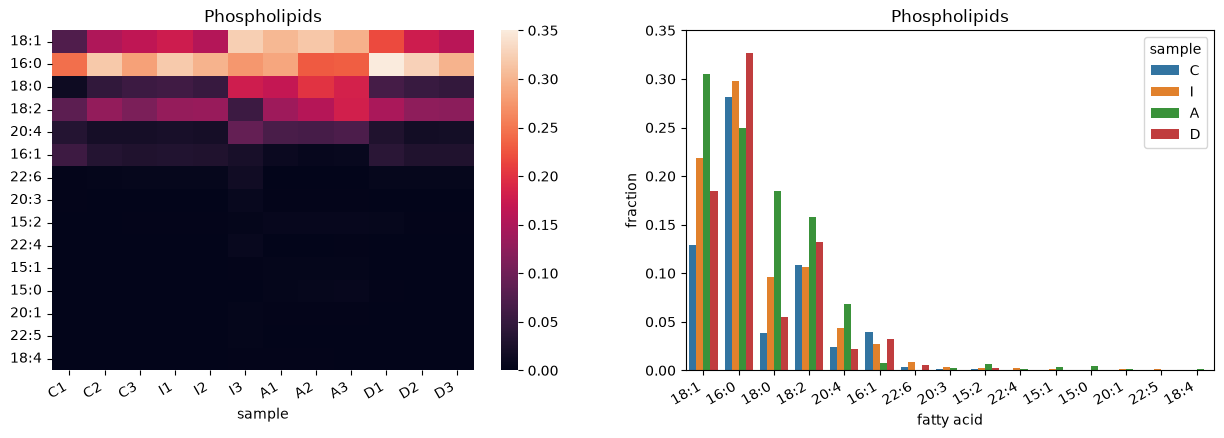

In [49]:
graph_fatty_acids(areas_tg, 'Triglycerides')
graph_fatty_acids(areas_phospho, 'Phospholipids')

C:\Users\steph\AppData\Local\Temp\ipykernel_32792\2106365907.py:24: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(x='kind', y='fraction', hue='sample', hue_order = hue_order_list,data=a, ci=None)


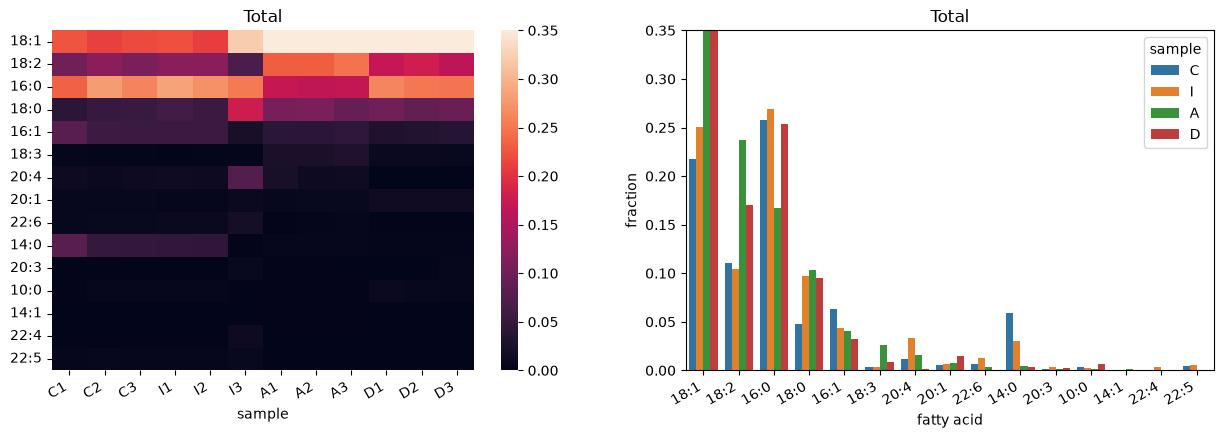

In [50]:
graph_fatty_acids(areas_total, 'Total')

C:\Users\steph\AppData\Local\Temp\ipykernel_32792\4248012791.py:9: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(x='sample', y='fraction', hue='kind',data=a, ci=None)
C:\Users\steph\AppData\Local\Temp\ipykernel_32792\4248012791.py:9: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(x='sample', y='fraction', hue='kind',data=a, ci=None)


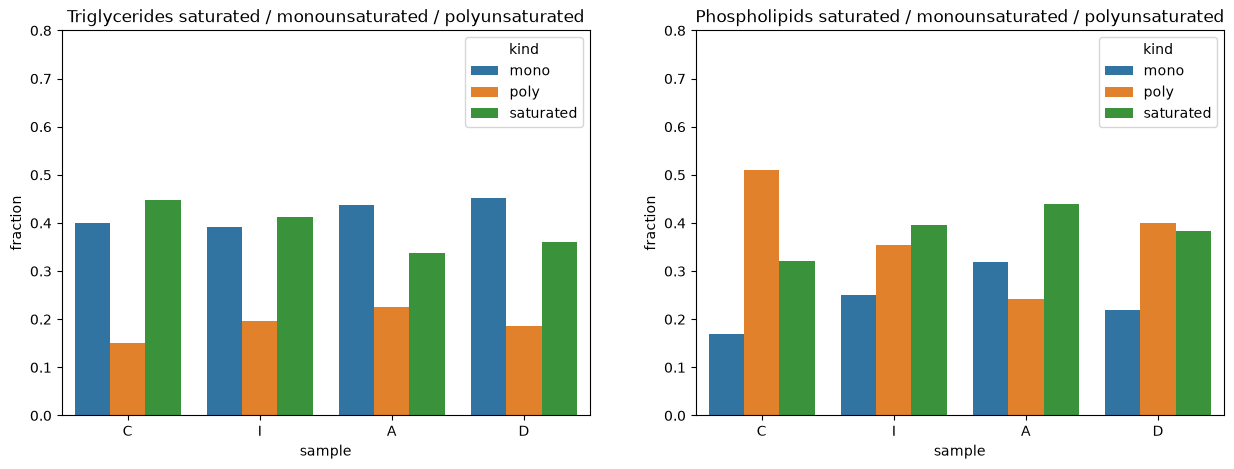

In [51]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
graph_saturation(areas_tg, 'Triglycerides')
plt.subplot(1, 2, 2)
graph_saturation(areas_phospho, 'Phospholipids')

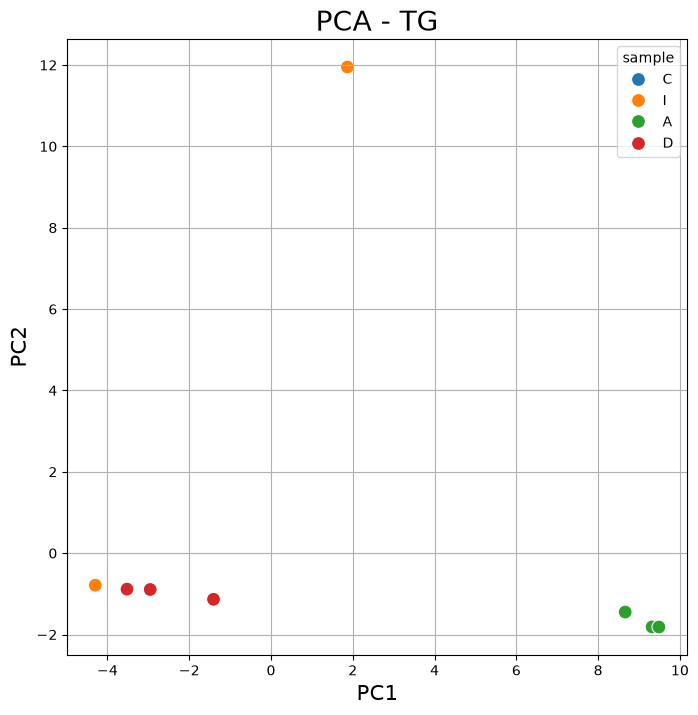

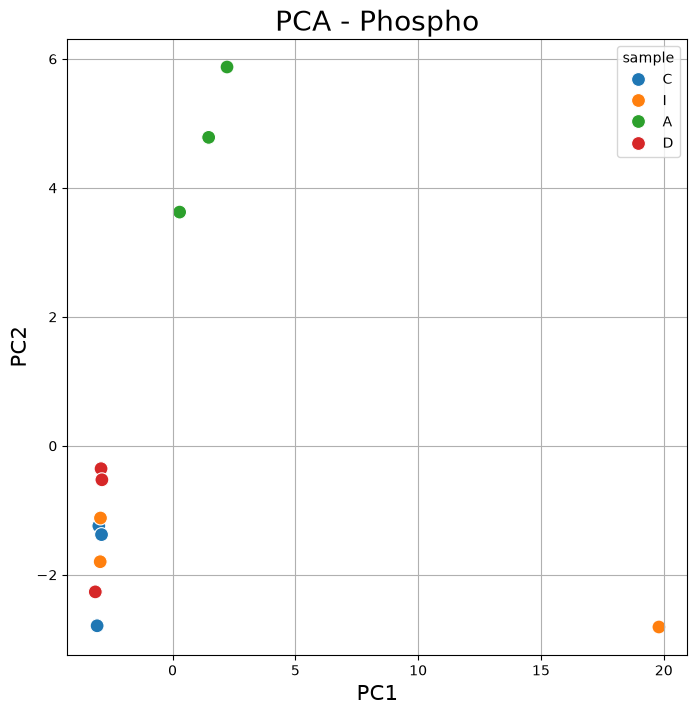

In [52]:
loading_vectors_tg, pca_tg = run_pca(areas_tg)
graph_pca(pca_tg, 'TG')
loading_vectors_phospho, pca_phospho = run_pca(areas_phospho)
graph_pca(pca_phospho, 'Phospho')